# Machine Learning Classification Model

In [ ]:
???

,change_tomorrow_direction,prediction
Date,,
2016-12-08,UP,UP
2016-12-09,UP,UP
...,...,...
2023-03-14,UP,DOWN
2023-03-15,UP,UP


## Load the data

In [1]:
import pandas as pd

df = pd.read_excel('data/Nvidia_Mellanox_Processed.xlsx', parse_dates=['Date'], index_col=0)
df

,Close,High,Low,Open,Volume,change_tomorrow,change_tomorrow_direction
Date,,,,,,,
2019-03-11,4.028500,4.051500,3.742250,3.789750,859728000,0.849129,UP
2019-03-12,4.063000,4.109750,3.979750,4.056500,579576000,3.617594,UP
2019-03-13,4.215500,4.245000,4.093250,4.100750,768900000,-1.848271,DOWN
2019-03-14,4.139000,4.236750,4.131250,4.224750,519384000,2.502804,UP
2019-03-15,4.245250,4.288250,4.179000,4.182500,661484000,-0.509029,DOWN
...,...,...,...,...,...,...,...
2024-12-27,137.009995,139.020004,134.710007,138.550003,170582600,0.349124,UP
2024-12-30,137.490005,140.270004,134.020004,134.830002,167734700,-2.382912,DOWN
2024-12-31,134.289993,138.070007,133.830002,138.029999,155659200,2.906517,UP


## Machine Learning Model

### Separate the data

1. Target: which variable do you want to predict?
2. Explanatory: which variables will you use to calculate the prediction?

In [2]:
target = df.change_tomorrow_direction
explanatory = df[['Open','High','Low','Close','Volume']]

### Compute the model

The following Python code will compute the numbers of the mathematical equation that we will use to calculate if the ticker goes UP or DOWN.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

model_dt = DecisionTreeClassifier(max_depth=15)
model_rf = RandomForestClassifier(n_estimators=100)
model_dt.fit(explanatory, target)
model_rf.fit(explanatory, target)

RandomForestClassifier()

### Visualize the model

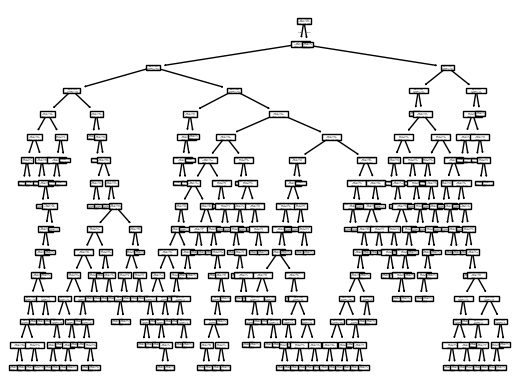

In [4]:
from sklearn.tree import plot_tree

plot_tree(decision_tree=model_dt, feature_names=model_dt.feature_names_in_);

### Calculate the predictions

In [5]:
explanatory

,Open,High,Low,Close,Volume
Date,,,,,
2019-03-11,3.789750,4.051500,3.742250,4.028500,859728000
2019-03-12,4.056500,4.109750,3.979750,4.063000,579576000
2019-03-13,4.100750,4.245000,4.093250,4.215500,768900000
2019-03-14,4.224750,4.236750,4.131250,4.139000,519384000
2019-03-15,4.182500,4.288250,4.179000,4.245250,661484000
...,...,...,...,...,...
2024-12-27,138.550003,139.020004,134.710007,137.009995,170582600
2024-12-30,134.830002,140.270004,134.020004,137.490005,167734700
2024-12-31,138.029999,138.070007,133.830002,134.289993,155659200


In [28]:
y_pred = model_dt.predict(X=explanatory)
y_pred = model_rf.predict(X=explanatory)
y_pred

array(['UP', 'UP', 'DOWN', ..., 'UP', 'UP', 'UP'], dtype=object)

In [29]:
df_predictions = df[['change_tomorrow_direction']].copy()
df_predictions['prediction'] = y_pred
df_predictions

,change_tomorrow_direction,prediction
Date,,
2019-03-11,UP,UP
2019-03-12,UP,UP
2019-03-13,DOWN,DOWN
2019-03-14,UP,UP
2019-03-15,DOWN,DOWN
...,...,...
2024-12-27,UP,UP
2024-12-30,DOWN,DOWN
2024-12-31,UP,UP


### Evaluate the model: compare predictions with the reality

In [30]:
comp = df_predictions.change_tomorrow_direction == df_predictions.prediction

In [31]:
comp.sum()

1466

In [32]:
len(comp)

1466

In [33]:
comp.sum()/len(comp)

1.0

## Save the model into a file

- We'll write the numbers of the Decision Tree's mathematical equation into a file.

In [34]:
import pickle

In [35]:
with open('models/model_rf_classification.pkl', 'wb') as f:
    pickle.dump(model_rf, f)